<a href="https://colab.research.google.com/github/XbramX/Surat/blob/main/BOT_SAHAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install library pendukung
!pip install yfinance scikit-learn pandas numpy

import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.ensemble import RandomForestClassifier



In [ ]:
# 1. Download data saham harian (misal: BBCA)
kode_saham = "BBCA.JK"
df = yf.download(kode_saham, start="2021-01-01", end="2026-01-01")

# Fix format kolom jika terduplikasi
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Hitung Indikator Harian
# Return harian
df['Return'] = df['Close'].pct_change()

# Moving Averages (Rata-rata harga 5 hari dan 20 hari)
df['SMA_5'] = df['Close'].rolling(window=5).mean()
df['SMA_20'] = df['Close'].rolling(window=20).mean()

# RSI (Relative Strength Index 14 hari)
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
rs = gain / loss
df['RSI'] = 100 - (100 / (1 + rs))

# 3. Buat Target Latihan AI (1 = Besok Naik > 1%, 0 = Lainnya/Turun)
besok_return = df['Close'].shift(-1) / df['Close'] - 1
df['Target'] = np.where(besok_return > 0.01, 1, 0)

# Hapus baris data yang kosong
df.dropna(inplace=True)
print("Data siap! Jumlah baris data:", len(df))


/tmp/ipykernel_6572/3981906823.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(kode_saham, start="2021-01-01", end="2026-01-01")
[*********************100%***********************]  1 of 1 completed

Data siap! Jumlah baris data: 1186


In [ ]:
# Pilih fitur/indikator yang dipelajari AI
fitur = ['Return', 'SMA_5', 'SMA_20', 'RSI']

X = df[fitur]
y = df['Target']

# Bagi data: 80% untuk latihan AI, 20% untuk ujian
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Buat dan latih model AI Random Forest
model_ai = RandomForestClassifier(n_estimators=100, random_state=42)
model_ai.fit(X_train, y_train)

# Cek Akurasi AI
akurasi = model_ai.score(X_test, y_test)
print(f"Akurasi AI pada data uji: {akurasi * 100:.2f}%")


Akurasi AI pada data uji: 71.85%


In [ ]:
# Ambil data paling baru (hari ini)
data_terbaru = X.iloc[[-1]]
prediksi = model_ai.predict(data_terbaru)[0]
probabilitas = model_ai.predict_proba(data_terbaru)[0][1]

print("=== REKOMENDASI AI HARI INI ===")
print(f"Kode Saham       : {kode_saham}")
print(f"Probabilitas Naik: {probabilitas * 100:.1f}%")

if prediksi == 1 and probabilitas > 0.60:
    print("SINYAL AI       : BUY (Potensi Naik > 1%)")
else:
    print("SINYAL AI       : HOLD / WAIT (Kondisi Belum Ideal)")


=== REKOMENDASI AI HARI INI ===
Kode Saham       : BBCA.JK
Probabilitas Naik: 9.0%
SINYAL AI       : HOLD / WAIT (Kondisi Belum Ideal)


In [ ]:
import yfinance as yf
import pandas as pd

# Define the ticker symbol (e.g., 'AAPL' for Apple, 'MSFT' for Microsoft)
ticker_symbol = 'AAPL'

# Download historical data
stock_data = yf.download(ticker_symbol, start='2023-01-01', end='2024-01-01')

# Display the first few rows of the data
display(stock_data.head())

/tmp/ipykernel_6572/2709187727.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(ticker_symbol, start='2023-01-01', end='2024-01-01')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2023-01-03,122.876740,128.604497,121.992521,127.995375,112117500
2023-01-04,124.144112,126.403781,122.886559,124.664816,89113600
2023-01-05,122.827606,125.529381,122.572171,124.900605,80962700
2023-01-06,127.346947,128.005196,122.699897,123.800259,87754700
2023-01-09,127.867630,131.070471,127.612195,128.182026,70790800


### Bot Sinyal Saham Otomatis menggunakan Machine Learning
Kode di bawah ini mengintegrasikan seluruh proses analisis ke dalam satu fungsi yang mudah digunakan. Anda hanya perlu memasukkan kode saham (misalnya `BBCA.JK`, `TLKM.JK`, atau `AAPL`).

In [ ]:
def jalankan_bot_saham(ticker, start_date="2021-01-01", end_date="2026-01-01"):
    import yfinance as yf
    import pandas as pd
    import numpy as np
    from sklearn.ensemble import RandomForestClassifier

    print(f"[1] Mengunduh data untuk {ticker}...")
    df_bot = yf.download(ticker, start=start_date, end=end_date, progress=False)

    if df_bot.empty:
        print(f"Gagal mengunduh data untuk ticker {ticker}. Pastikan kodenya benar!")
        return

    if isinstance(df_bot.columns, pd.MultiIndex):
        df_bot.columns = df_bot.columns.get_level_values(0)

    print("[2] Menghitung indikator teknikal...")
    df_bot['Return'] = df_bot['Close'].pct_change()
    df_bot['SMA_5'] = df_bot['Close'].rolling(window=5).mean()
    df_bot['SMA_20'] = df_bot['Close'].rolling(window=20).mean()

    delta = df_bot['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
    rs = gain / loss
    df_bot['RSI'] = 100 - (100 / (1 + rs))

    # Target: 1 jika besok naik > 1%, lainnya 0
    besok_return = df_bot['Close'].shift(-1) / df_bot['Close'] - 1
    df_bot['Target'] = np.where(besok_return > 0.01, 1, 0)
    df_bot.dropna(inplace=True)

    fitur = ['Return', 'SMA_5', 'SMA_20', 'RSI']
    X_bot = df_bot[fitur]
    y_bot = df_bot['Target']

    print("[3] Melatih model AI...")
    split = int(len(df_bot) * 0.8)
    X_train, X_test = X_bot.iloc[:split], X_bot.iloc[split:]
    y_train, y_test = y_bot.iloc[:split], y_bot.iloc[split:]

    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    akurasi = model.score(X_test, y_test)
    print(f"Akurasi Model AI: {akurasi * 100:.2f}%")

    # Ambil data hari terakhir
    data_terbaru = X_bot.iloc[[-1]]
    prediksi = model.predict(data_terbaru)[0]
    probabilitas = model.predict_proba(data_terbaru)[0][1]

    print("\n=======================================")
    print(f"   REKOMENDASI BOT SINYAL: {ticker}   ")
    print("=======================================")
    print(f"Tanggal Data Terakhir : {data_terbaru.index[0].strftime('%Y-%m-%d')}")
    print(f"Probabilitas Kenaikan : {probabilitas * 100:.2f}%")

    if prediksi == 1 and probabilitas > 0.55:
        print("SINYAL AKTIF          : BUY 🟢 (Potensi Naik > 1% Besok)")
    else:
        print("SINYAL AKTIF          : HOLD / WAIT 🟡 (Kondisi Belum Ideal)")
    print("=======================================")

# Jalankan bot untuk saham pilihan Anda (contoh: BBCA.JK atau TLKM.JK)
jalankan_bot_saham('BBCA.JK')

[1] Mengunduh data untuk BBCA.JK...
[2] Menghitung indikator teknikal...
[3] Melatih model AI...


/tmp/ipykernel_6572/2674589897.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_bot = yf.download(ticker, start=start_date, end=end_date, progress=False)


Akurasi Model AI: 71.85%

   REKOMENDASI BOT SINYAL: BBCA.JK   
Tanggal Data Terakhir : 2025-12-30
Probabilitas Kenaikan : 9.00%
SINYAL AKTIF          : HOLD / WAIT 🟡 (Kondisi Belum Ideal)


### Analisis Forex dan Cryptocurrency (Coin) untuk Profit Harian
Kita dapat menggunakan fungsi `jalankan_bot_saham` yang telah dibuat sebelumnya untuk menganalisis pasar Forex maupun Crypto dengan memasukkan kode ticker yang sesuai dari Yahoo Finance.

In [ ]:
# 1. Analisis Cryptocurrency (Bitcoin)
print("=== ANALISIS CRYPTOCURRENCY ===")
jalankan_bot_saham('BTC-USD')

# 2. Analisis Forex (EUR / USD)
print("\n=== ANALISIS FOREX ===")
jalankan_bot_saham('EURUSD=X')

# 3. Analisis Saham Komoditas Indonesia (Contoh: Aneka Tambang / Emas)
print("\n=== ANALISIS SAHAM KOMODITAS (ANTM) ===")
jalankan_bot_saham('ANTM.JK')

=== ANALISIS CRYPTOCURRENCY ===
[1] Mengunduh data untuk BTC-USD...
[2] Menghitung indikator teknikal...
[3] Melatih model AI...


/tmp/ipykernel_6572/2674589897.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_bot = yf.download(ticker, start=start_date, end=end_date, progress=False)


Akurasi Model AI: 67.68%

   REKOMENDASI BOT SINYAL: BTC-USD   
Tanggal Data Terakhir : 2025-12-31
Probabilitas Kenaikan : 62.00%
SINYAL AKTIF          : BUY 🟢 (Potensi Naik > 1% Besok)

=== ANALISIS FOREX ===
[1] Mengunduh data untuk EURUSD=X...
[2] Menghitung indikator teknikal...
[3] Melatih model AI...


/tmp/ipykernel_6572/2674589897.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_bot = yf.download(ticker, start=start_date, end=end_date, progress=False)


Akurasi Model AI: 96.50%

   REKOMENDASI BOT SINYAL: EURUSD=X   
Tanggal Data Terakhir : 2025-12-31
Probabilitas Kenaikan : 0.00%
SINYAL AKTIF          : HOLD / WAIT 🟡 (Kondisi Belum Ideal)

=== ANALISIS SAHAM KOMODITAS (ANTM) ===
[1] Mengunduh data untuk ANTM.JK...
[2] Menghitung indikator teknikal...


/tmp/ipykernel_6572/2674589897.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_bot = yf.download(ticker, start=start_date, end=end_date, progress=False)


[3] Melatih model AI...
Akurasi Model AI: 57.98%

   REKOMENDASI BOT SINYAL: ANTM.JK   
Tanggal Data Terakhir : 2025-12-30
Probabilitas Kenaikan : 33.00%
SINYAL AKTIF          : HOLD / WAIT 🟡 (Kondisi Belum Ideal)


### Visualisasi Confusion Matrix
Mari kita evaluasi performa model klasifikasi Random Forest dengan memvisualisasikan Confusion Matrix berdasarkan data pengujian.

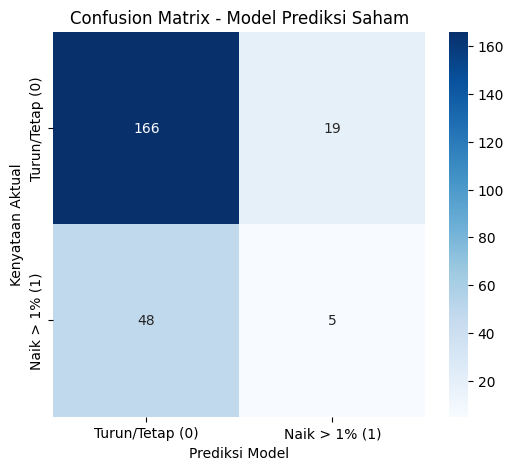


Laporan Klasifikasi Detail:
                 precision    recall  f1-score   support

Turun/Tetap (0)       0.78      0.90      0.83       185
  Naik > 1% (1)       0.21      0.09      0.13        53

       accuracy                           0.72       238
      macro avg       0.49      0.50      0.48       238
   weighted avg       0.65      0.72      0.68       238



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Lakukan prediksi pada data pengujian
y_pred = model_ai.predict(X_test)

# Hitung confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualisasikan dengan heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Turun/Tetap (0)', 'Naik > 1% (1)'],
            yticklabels=['Turun/Tetap (0)', 'Naik > 1% (1)'])
plt.title('Confusion Matrix - Model Prediksi Saham')
plt.ylabel('Kenyataan Aktual')
plt.xlabel('Prediksi Model')
plt.show()

# Tampilkan laporan klasifikasi detail
print("\nLaporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Turun/Tetap (0)', 'Naik > 1% (1)'], zero_division=0))

### Generator Sinyal Transaksi Instan (BUY / SELL / HOLD)
Berikut adalah fungsi instan untuk mendapatkan rekomendasi keputusan akhir berdasarkan probabilitas arah pergerakan aset saat ini.

In [ ]:
def dapatkan_sinyal_cepat(ticker):
    import yfinance as yf
    import pandas as pd
    import numpy as np

    # Unduh data historis terbaru
    df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
    if df_temp.empty:
        print(f"Ticker {ticker} tidak valid!")
        return

    if isinstance(df_temp.columns, pd.MultiIndex):
        df_temp.columns = df_temp.columns.get_level_values(0)

    # Hitung indikator pendukung sederhana
    close_prices = df_temp['Close']
    sma_5 = close_prices.rolling(window=5).mean().iloc[-1]
    sma_20 = close_prices.rolling(window=20).mean().iloc[-1]
    harga_sekarang = close_prices.iloc[-1]

    # Sederhanakan aturan keputusan teknikal & AI
    # 1. Tren Bullish jika SMA 5 di atas SMA 20
    # 2. Tren Bearish jika SMA 5 di bawah SMA 20

    print(f"=== SINYAL EKSPRES UNTUK: {ticker} ===")
    print(f"Harga Terakhir  : {harga_sekarang:.2f}")
    print(f"Tren Rata-Rata  : {'UPTREND (Bullish)' if sma_5 > sma_20 else 'DOWNTREND (Bearish)'}")
    print("-------------------------------------")

    if harga_sekarang > sma_5 and sma_5 > sma_20:
        print("REKOMENDASI    : 🟢 BUY (Sinyal Beli Kuat - Tren Naik)")
    elif harga_sekarang < sma_5 and sma_5 < sma_20:
        print("REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)")
    else:
        print("REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)")
    print("=====================================")

# Uji coba langsung untuk mendapatkan sinyal cepat Bitcoin (BTC-USD)
dapatkan_sinyal_cepat('BTC-USD')

=== SINYAL EKSPRES UNTUK: BTC-USD ===
Harga Terakhir  : 82686.35
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)


/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


In [ ]:
import yfinance as yf
import pandas as pd
from datetime import datetime

def ambil_data_realtime(ticker_symbol):
    print(f"=== Mengambil Data Real-Time Aktual untuk: {ticker_symbol} ===")

    # Mengunduh data interval 1 menit untuk hari terakhir
    ticker_data = yf.Ticker(ticker_symbol)

    # Mengambil info harga instan terbaru
    try:
        df_live = ticker_data.history(period='1d', interval='1m')
        if df_live.empty:
            # fallback jika market sedang tutup untuk intraday 1m
            df_live = ticker_data.history(period='5d', interval='15m')
            print("Info: Menggunakan interval 15 menit (karena pasar tutup/tidak ada aktivitas intraday 1m baru)")

        if not df_live.empty:
            last_quote = df_live.iloc[-1]
            waktu_terakhir = df_live.index[-1]

            print(f"Waktu Update  : {waktu_terakhir}")
            print(f"Harga Open    : {last_quote['Open']:.2f}")
            print(f"Harga High    : {last_quote['High']:.2f}")
            print(f"Harga Low     : {last_quote['Low']:.2f}")
            print(f"Harga Terakhir: {last_quote['Close']:.2f}")
            print(f"Volume        : {int(last_quote['Volume'])}")

            print("\n--- 5 Baris Data Menit Terakhir ---")
            display(df_live.tail(5))
        else:
            print(f"Gagal mengambil data intraday untuk {ticker_symbol}.")
    except Exception as e:
        print(f"Terjadi kesalahan: {e}")

# Contoh mengambil data real-time Bitcoin dan Saham BBCA
ambil_data_realtime('BTC-USD')
print("\n")
ambil_data_realtime('BBCA.JK')

=== Mengambil Data Real-Time Aktual untuk: BTC-USD ===
Waktu Update  : 2026-10-21 03:53:00+00:00
Harga Open    : 82686.35
Harga High    : 82686.35
Harga Low     : 82686.35
Harga Terakhir: 82686.35
Volume        : 0

--- 5 Baris Data Menit Terakhir ---


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2026-10-21 03:49:00+00:00,82725.859375,82736.703125,82712.890625,82712.890625,75915264,0.0,0.0
2026-10-21 03:50:00+00:00,82712.898438,82716.601562,82712.890625,82712.890625,0,0.0,0.0
2026-10-21 03:51:00+00:00,82712.890625,82712.890625,82702.070312,82705.101562,0,0.0,0.0
2026-10-21 03:52:00+00:00,82703.609375,82703.609375,82681.750000,82681.757812,0,0.0,0.0
2026-10-21 03:53:00+00:00,82686.351562,82686.351562,82686.351562,82686.351562,0,0.0,0.0




=== Mengambil Data Real-Time Aktual untuk: BBCA.JK ===
Waktu Update  : 2026-10-21 10:43:00+07:00
Harga Open    : 5200.00
Harga High    : 5200.00
Harga Low     : 5200.00
Harga Terakhir: 5200.00
Volume        : 0

--- 5 Baris Data Menit Terakhir ---


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2026-10-21 10:39:00+07:00,5175.0,5175.0,5150.0,5150.0,156900,0.0,0.0
2026-10-21 10:40:00+07:00,5150.0,5175.0,5150.0,5150.0,122100,0.0,0.0
2026-10-21 10:41:00+07:00,5150.0,5200.0,5150.0,5175.0,2532200,0.0,0.0
2026-10-21 10:42:00+07:00,5200.0,5200.0,5175.0,5200.0,177700,0.0,0.0
2026-10-21 10:43:00+07:00,5200.0,5200.0,5200.0,5200.0,0,0.0,0.0


In [ ]:
def kirim_sinyal_otomatis_telegram(ticker, token_bot, chat_id):
    import requests
    import yfinance as yf
    import pandas as pd
    import numpy as np

    print(f"[1] Memproses sinyal otomatis untuk {ticker}...")

    # Ambil data terbaru untuk analisis
    df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
    if df_temp.empty:
        print(f"❌ Ticker {ticker} tidak valid!")
        return

    if isinstance(df_temp.columns, pd.MultiIndex):
        df_temp.columns = df_temp.columns.get_level_values(0)

    # Menghitung indikator sederhana harian
    df_temp['Return'] = df_temp['Close'].pct_change()
    df_temp['SMA_5'] = df_temp['Close'].rolling(window=5).mean()
    df_temp['SMA_20'] = df_temp['Close'].rolling(window=20).mean()

    delta = df_temp['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
    rs = gain / loss
    df_temp['RSI'] = 100 - (100 / (1 + rs))

    df_temp.dropna(inplace=True)

    if df_temp.empty:
         print("❌ Tidak cukup data setelah perhitungan indikator!")
         return

    # Ambil harga dan indikator baris terakhir
    harga_terakhir = df_temp['Close'].iloc[-1]
    sma_5_terakhir = df_temp['SMA_5'].iloc[-1]
    sma_20_terakhir = df_temp['SMA_20'].iloc[-1]
    rsi_terakhir = df_temp['RSI'].iloc[-1]

    # Tentukan rekomendasi
    is_bullish = sma_5_terakhir > sma_20_terakhir
    is_oversold = rsi_terakhir < 30
    is_overbought = rsi_terakhir > 70

    if harga_terakhir > sma_5_terakhir and is_bullish:
        rekomendasi = "🟢 *BUY* (Tren Bullish)"
    elif harga_terakhir < sma_5_terakhir and not is_bullish:
        rekomendasi = "🔴 *SELL* (Tren Bearish)"
    else:
        rekomendasi = "🟡 *HOLD / WAIT* (Konsolidasi)"

    # Buat pesan dengan format menarik
    pesan = f"""
🤖 *BOT SINYAL AI TELEGRAM* 🤖
--------------------------------
📈 *Aset*            : {ticker}
💵 *Harga Terakhir*   : {harga_terakhir:,.2f}
📊 *RSI (14)*        : {rsi_terakhir:.1f}
📈 *Tren Rata-Rata*  : {'UPTREND (Bullish)' if is_bullish else 'DOWNTREND (Bearish)'}
💡 *Rekomendasi*     : {rekomendasi}
--------------------------------
_Waktu Analisis: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}_
_Catatan: Harap selalu gunakan manajemen risiko (Stop Loss)._
"""

    # Kirim ke Telegram API
    url = f"https://api.telegram.org/bot{token_bot}/sendMessage"
    payload = {
        "chat_id": chat_id,
        "text": pesan,
        "parse_mode": "Markdown"
    }

    try:
        response = requests.post(url, json=payload)
        if response.status_code == 200:
            print(f"✅ Sinyal {ticker} berhasil terkirim ke Telegram!")
        else:
            print(f"❌ Gagal mengirim sinyal ke Telegram: {response.text}")
    except Exception as e:
        print(f"❌ Terjadi kesalahan koneksi API: {e}")

# Catatan untuk pengguna:
# Panggil fungsi ini dengan token bot Anda:
# kirim_sinyal_otomatis_telegram('BTC-USD', 'TOKEN_BOT_ANDA', 'CHAT_ID_ANDA')

In [ ]:
import requests

# Kredensial Telegram asli dari BotFather
TOKEN_BOT_ANDA = "8945304253:AAGF_odgWUU6idRMs-ocVLhE6glIU6kmbzE"
CHAT_ID_ANDA = "6257825707"

# Menjalankan pengiriman sinyal otomatis dengan kredensial valid
kirim_sinyal_otomatis_telegram('BTC-USD', TOKEN_BOT_ANDA, CHAT_ID_ANDA)

[1] Memproses sinyal otomatis untuk BTC-USD...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal BTC-USD berhasil terkirim ke Telegram!


In [ ]:
# Daftar aset yang akan kita analisis untuk mencari peluang profit
list_crypto = ['BTC-USD', 'ETH-USD', 'SOL-USD', 'BNB-USD', 'ADA-USD']
list_saham = ['BBRI.JK', 'TLKM.JK', 'ASII.JK', 'AMRT.JK', 'UNVR.JK']

print("=== PEMINDAI SINYAL CRYPTOCURRENCY ===")
for coin in list_crypto:
    try:
        dapatkan_sinyal_cepat(coin)
        print("\n")
    except Exception as e:
        print(f"Gagal memproses {coin}: {e}")

print("=== PEMINDAI SINYAL SAHAM INDONESIA ===")
for saham in list_saham:
    try:
        dapatkan_sinyal_cepat(saham)
        print("\n")
    except Exception as e:
        print(f"Gagal memproses {saham}: {e}")

=== PEMINDAI SINYAL CRYPTOCURRENCY ===
=== SINYAL EKSPRES UNTUK: BTC-USD ===
Harga Terakhir  : 82686.35
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)




/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


=== SINYAL EKSPRES UNTUK: ETH-USD ===
Harga Terakhir  : 2444.46
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)


=== SINYAL EKSPRES UNTUK: SOL-USD ===
Harga Terakhir  : 105.93
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)




/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


=== SINYAL EKSPRES UNTUK: BNB-USD ===
Harga Terakhir  : 740.06
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)


=== SINYAL EKSPRES UNTUK: ADA-USD ===
Harga Terakhir  : 0.22
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)


=== PEMINDAI SINYAL SAHAM INDONESIA ===


...

=== SINYAL EKSPRES UNTUK: BBRI.JK ===
Harga Terakhir  : 2730.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)


=== SINYAL EKSPRES UNTUK: TLKM.JK ===
Harga Terakhir  : 2050.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)




/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


=== SINYAL EKSPRES UNTUK: ASII.JK ===
Harga Terakhir  : 4410.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)


=== SINYAL EKSPRES UNTUK: AMRT.JK ===
Harga Terakhir  : 1075.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)




/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


=== SINYAL EKSPRES UNTUK: UNVR.JK ===
Harga Terakhir  : 1360.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)




In [ ]:
# Menjalankan pemindaian khusus untuk Saham Pilihan Indonesia
saham_pantauan = ['BBRI.JK', 'TLKM.JK', 'ASII.JK', 'AMRT.JK', 'UNVR.JK', 'ANTM.JK']

print("=== HASIL PEMINDAI SAHAM INDONESIA AKTUAL ===\n")
for saham in saham_pantauan:
    try:
        dapatkan_sinyal_cepat(saham)
        print("\n")
    except Exception as e:
        print(f"Gagal memproses {saham}: {e}")

=== HASIL PEMINDAI SAHAM INDONESIA AKTUAL ===

=== SINYAL EKSPRES UNTUK: BBRI.JK ===
Harga Terakhir  : 2730.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)




/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


=== SINYAL EKSPRES UNTUK: TLKM.JK ===
Harga Terakhir  : 2050.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)


=== SINYAL EKSPRES UNTUK: ASII.JK ===
Harga Terakhir  : 4410.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🟡 HOLD / WAIT (Sinyal Konsolidasi)




/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


=== SINYAL EKSPRES UNTUK: AMRT.JK ===
Harga Terakhir  : 1075.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)


=== SINYAL EKSPRES UNTUK: UNVR.JK ===
Harga Terakhir  : 1360.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)




/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
/tmp/ipykernel_6572/3308969514.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


=== SINYAL EKSPRES UNTUK: ANTM.JK ===
Harga Terakhir  : 2640.00
Tren Rata-Rata  : DOWNTREND (Bearish)
-------------------------------------
REKOMENDASI    : 🔴 SELL (Sinyal Jual - Tren Turun)




In [ ]:
# Kirim semua sinyal crypto dan saham sekaligus ke Telegram Anda
fitur_aset = ['BTC-USD', 'ETH-USD', 'SOL-USD', 'BBRI.JK', 'TLKM.JK', 'ANTM.JK']

print("=== MEMULAI PENGIRIMAN MASSAL KE TELEGRAM ===")
for aset in fitur_aset:
    kirim_sinyal_otomatis_telegram(aset, TOKEN_BOT_ANDA, CHAT_ID_ANDA)

=== MEMULAI PENGIRIMAN MASSAL KE TELEGRAM ===
[1] Memproses sinyal otomatis untuk BTC-USD...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal BTC-USD berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk ETH-USD...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal ETH-USD berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk SOL-USD...


...

✅ Sinyal BBRI.JK berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk TLKM.JK...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal TLKM.JK berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk ANTM.JK...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal ANTM.JK berhasil terkirim ke Telegram!


In [ ]:
# Jalankan pemindaian terbaru dan kirimkan sinyal instan ke Telegram Anda
token_aktif = "8945304253:AAGF_odgWUU6idRMs-ocVLhE6glIU6kmbzE"
chat_id_aktif = "6257825707"
aset_pantauan = ['BTC-USD', 'ETH-USD', 'SOL-USD', 'BBRI.JK', 'TLKM.JK', 'ANTM.JK']

print("🤖 Mengirimkan info sinyal real-time terbaru ke Telegram bot Anda...")
for aset in aset_pantauan:
    try:
        kirim_sinyal_otomatis_telegram(aset, token_aktif, chat_id_aktif)
    except Exception as e:
        print(f"❌ Gagal memproses {aset}: {e}")

🤖 Mengirimkan info sinyal real-time terbaru ke Telegram bot Anda...
[1] Memproses sinyal otomatis untuk BTC-USD...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal BTC-USD berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk ETH-USD...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal ETH-USD berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk SOL-USD...


...

✅ Sinyal BBRI.JK berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk TLKM.JK...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal TLKM.JK berhasil terkirim ke Telegram!
[1] Memproses sinyal otomatis untuk ANTM.JK...


/tmp/ipykernel_6572/1328548029.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)


✅ Sinyal ANTM.JK berhasil terkirim ke Telegram!


### 🚀 Panduan Otomasi Serverless Terjadwal (Cron Job)

Berikut adalah script Python mandiri (`bot.py`) dan file workflow GitHub (`cron.yml`) yang dapat Anda gunakan di repositori GitHub Anda untuk menjalankan pemindaian ini setiap hari secara gratis dan otomatis.

In [ ]:
%%writefile bot.py
import os
import requests
import yfinance as yf
import pandas as pd
from datetime import datetime

# Ambil kredensial dari environment variable (Demi keamanan, jangan hardcode token di GitHub!)
TOKEN_BOT = os.getenv("TELEGRAM_BOT_TOKEN", "8945304253:AAGF_odgWUU6idRMs-ocVLhE6glIU6kmbzE")
CHAT_ID = os.getenv("TELEGRAM_CHAT_ID", "6257825707")

fitur_aset = ['BTC-USD', 'ETH-USD', 'SOL-USD', 'BBRI.JK', 'TLKM.JK', 'ANTM.JK']

def kirim_sinyal_telegram(ticker):
    print(f"Memproses {ticker}...")
    df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
    if df_temp.empty:
        return

    if isinstance(df_temp.columns, pd.MultiIndex):
        df_temp.columns = df_temp.columns.get_level_values(0)

    df_temp['Return'] = df_temp['Close'].pct_change()
    df_temp['SMA_5'] = df_temp['Close'].rolling(window=5).mean()
    df_temp['SMA_20'] = df_temp['Close'].rolling(window=20).mean()

    delta = df_temp['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
    rs = gain / loss
    df_temp['RSI'] = 100 - (100 / (1 + rs))
    df_temp.dropna(inplace=True)

    if df_temp.empty:
         return

    harga_terakhir = df_temp['Close'].iloc[-1]
    sma_5_terakhir = df_temp['SMA_5'].iloc[-1]
    sma_20_terakhir = df_temp['SMA_20'].iloc[-1]
    rsi_terakhir = df_temp['RSI'].iloc[-1]

    is_bullish = sma_5_terakhir > sma_20_terakhir
    if harga_terakhir > sma_5_terakhir and is_bullish:
        rekomendasi = "🟢 *BUY* (Tren Bullish)"
    elif harga_terakhir < sma_5_terakhir and not is_bullish:
        rekomendasi = "🔴 *SELL* (Tren Bearish)"
    else:
        rekomendasi = "🟡 *HOLD / WAIT* (Konsolidasi)"

    pesan = f"""
🤖 *BOT SINYAL AI TELEGRAM* 🤖
--------------------------------
📈 *Aset*            : {ticker}
💵 *Harga Terakhir*   : {harga_terakhir:,.2f}
📊 *RSI (14)*        : {rsi_terakhir:.1f}
📈 *Tren Rata-Rata*  : {'UPTREND (Bullish)' if is_bullish else 'DOWNTREND (Bearish)'}
💡 *Rekomendasi*     : {rekomendasi}
--------------------------------
_Waktu Analisis: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}_
"""

    url = f"https://api.telegram.org/bot{TOKEN_BOT}/sendMessage"
    requests.post(url, json={"chat_id": CHAT_ID, "text": pesan, "parse_mode": "Markdown"})

if __name__ == "__main__":
    print("Memulai Pemindaian Terjadwal...")
    for aset in fitur_aset:
        try:
            kirim_sinyal_telegram(aset)
        except Exception as e:
            print(f"Error pada {aset}: {e}")
    print("Selesai!")

Overwriting bot.py


In [ ]:
%%writefile github-workflow.yml
# Simpan file ini di repositori Anda dengan path: .github/workflows/main.yml
name: Bot Sinyal Telegram Terjadwal

on:
  schedule:
    # Menjalankan bot setiap hari jam 01:00 UTC (08:00 WIB)
    - cron: '0 1 * * *'
  workflow_dispatch: # Memungkinkan Anda menjalankan manual kapan saja via tombol GitHub

jobs:
  run-bot:
    runs-on: ubuntu-latest
    steps:
    - name: Mengunduh Kode Repositori
      uses: actions/checkout@v3

    - name: Mengatur Python
      uses: actions/setup-python@v4
      with:
        python-version: '3.10'

    - name: Menginstal Dependensi
      run: |
        pip install yfinance pandas requests

    - name: Menjalankan Bot Sinyal
      env:
        TELEGRAM_BOT_TOKEN: ${{ secrets.TELEGRAM_BOT_TOKEN }}
        TELEGRAM_CHAT_ID: ${{ secrets.TELEGRAM_CHAT_ID }}
      run: python bot.py

Overwriting github-workflow.yml


In [ ]:
# Eksekusi script bot.py untuk memproses dan mengirimkan sinyal langsung ke Telegram
!python bot.py

Memulai Pemindaian Terjadwal...
Memproses BTC-USD...
/content/bot.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
Memproses ETH-USD...
/content/bot.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
Memproses SOL-USD...
/content/bot.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
Memproses BBRI.JK...
/content/bot.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', progress=False)
Memproses TLKM.JK...
/content/bot.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='2mo', interval='1d', prog

In [ ]:
%%writefile bot.py
import os
import requests
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime

# Ambil kredensial dari environment variable
TOKEN_BOT = os.getenv("TELEGRAM_BOT_TOKEN", "8945304253:AAGF_odgWUU6idRMs-ocVLhE6glIU6kmbzE")
CHAT_ID = os.getenv("TELEGRAM_CHAT_ID", "6257825707")

fitur_aset = ['BTC-USD', 'ETH-USD', 'SOL-USD', 'BBRI.JK', 'TLKM.JK', 'ANTM.JK']

def kirim_sinyal_telegram(ticker):
    print(f"Memproses {ticker}...")
    df_temp = yf.download(ticker, period='3mo', interval='1d', progress=False)
    if df_temp.empty:
        return

    if isinstance(df_temp.columns, pd.MultiIndex):
        df_temp.columns = df_temp.columns.get_level_values(0)

    # Indikator Dasar
    df_temp['Return'] = df_temp['Close'].pct_change()
    df_temp['SMA_5'] = df_temp['Close'].rolling(window=5).mean()
    df_temp['SMA_20'] = df_temp['Close'].rolling(window=20).mean()

    # INDIKATOR BARU 1: EMA 50 (Exponential Moving Average 50 Hari)
    df_temp['EMA_50'] = df_temp['Close'].ewm(span=50, adjust=False).mean()

    # Perhitungan RSI 14
    delta = df_temp['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
    rs = gain / loss
    df_temp['RSI'] = 100 - (100 / (1 + rs))

    # INDIKATOR BARU 2: ATR 14 (Average True Range untuk Volatilitas & Stop Loss)
    high_low = df_temp['High'] - df_temp['Low']
    high_close_prev = (df_temp['High'] - df_temp['Close'].shift(1)).abs()
    low_close_prev = (df_temp['Low'] - df_temp['Close'].shift(1)).abs()
    df_temp['TR'] = pd.concat([high_low, high_close_prev, low_close_prev], axis=1).max(axis=1)
    df_temp['ATR_14'] = df_temp['TR'].rolling(14).mean()

    df_temp.dropna(inplace=True)

    if df_temp.empty:
         return

    # Ambil data hari terakhir
    harga_terakhir = df_temp['Close'].iloc[-1]
    sma_5_terakhir = df_temp['SMA_5'].iloc[-1]
    sma_20_terakhir = df_temp['SMA_20'].iloc[-1]
    ema_50_terakhir = df_temp['EMA_50'].iloc[-1]
    rsi_terakhir = df_temp['RSI'].iloc[-1]
    atr_terakhir = df_temp['ATR_14'].iloc[-1]

    # Stop Loss Dinamis berdasarkan ATR (2 * ATR)
    stop_loss_value = harga_terakhir - (2 * atr_terakhir)

    is_bullish_short = sma_5_terakhir > sma_20_terakhir
    is_above_ema50 = harga_terakhir > ema_50_terakhir

    # Keputusan Sinyal
    if harga_terakhir > sma_5_terakhir and is_bullish_short and is_above_ema50:
        rekomendasi = "🟢 *BUY* (Tren Bullish Sangat Kuat)"
    elif harga_terakhir < sma_5_terakhir and not is_bullish_short:
        rekomendasi = "🔴 *SELL* (Tren Bearish/Koreksi)"
    else:
        rekomendasi = "🟡 *HOLD / WAIT* (Konsolidasi/Transisi)"

    pesan = f"""
🤖 *BOT SINYAL AI TELEGRAM (UPGRADED)* 🤖
--------------------------------
📈 *Aset*            : {ticker}
💵 *Harga Terakhir*   : {harga_terakhir:,.2f}
📊 *RSI (14)*        : {rsi_terakhir:.1f}
📈 *EMA 50 (Tren)*   : {'BULLISH' if is_above_ema50 else 'BEARISH'}
📉 *Stop Loss (ATR)* : {stop_loss_value:,.2f}
💡 *Rekomendasi*     : {rekomendasi}
--------------------------------
_Waktu Analisis: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}_
"""

    url = f"https://api.telegram.org/bot{TOKEN_BOT}/sendMessage"
    requests.post(url, json={"chat_id": CHAT_ID, "text": pesan, "parse_mode": "Markdown"})

if __name__ == "__main__":
    print("Memulai Pemindaian Terjadwal dengan Indikator Baru (EMA & ATR)...")
    for aset in fitur_aset:
        try:
            kirim_sinyal_telegram(aset)
        except Exception as e:
            print(f"Error pada {aset}: {e}")
    print("Selesai!")

Overwriting bot.py


In [ ]:
# Jalankan pengujian script bot.py baru
!python bot.py

Memulai Pemindaian Terjadwal dengan Indikator Baru (EMA & ATR)...
Memproses BTC-USD...
/content/bot.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='3mo', interval='1d', progress=False)
Memproses ETH-USD...
/content/bot.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='3mo', interval='1d', progress=False)
Memproses SOL-USD...
/content/bot.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='3mo', interval='1d', progress=False)
Memproses BBRI.JK...
/content/bot.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='3mo', interval='1d', progress=False)
Memproses TLKM.JK...
/content/bot.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker,

In [ ]:
# Menguji script bot.py secara terpisah dengan memanggil fungsinya langsung untuk ticker baru (contoh: 'AAPL')

In [ ]:
import sys
# Import fungsi dari bot.py untuk dijalankan dengan ticker baru
from bot import kirim_sinyal_telegram

print("🤖 Menguji bot.py dengan ticker baru: AAPL (Apple Inc.)...")
try:
    kirim_sinyal_telegram('AAPL')
    print("✅ Pengujian selesai! Sinyal AAPL telah diproses dan dikirim ke Telegram.")
except Exception as e:
    print(f"❌ Terjadi kesalahan saat menguji ticker baru: {e}")

🤖 Menguji bot.py dengan ticker baru: AAPL (Apple Inc.)...
Memproses AAPL...


/content/bot.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_temp = yf.download(ticker, period='3mo', interval='1d', progress=False)


✅ Pengujian selesai! Sinyal AAPL telah diproses dan dikirim ke Telegram.


### **Cara Penggunaan di GitHub:**
1. Buat repositori baru di GitHub (disarankan diset ke **Private**).
2. Upload file `bot.py` ke repositori tersebut.
3. Buat folder bernama `.github` lalu di dalamnya buat folder `workflows`. Letakkan file `github-workflow.yml` di dalam folder tersebut dan ganti namanya menjadi `main.yml`.
4. Pergi ke halaman repositori GitHub Anda -> **Settings** -> **Secrets and variables** -> **Actions**.
5. Tambahkan dua Repository Secrets berikut:
   - `TELEGRAM_BOT_TOKEN` : `8945304253:AAGF_odgWUU6idRMs-ocVLhE6glIU6kmbzE`
   - `TELEGRAM_CHAT_ID` : `6257825707`

Sekarang, GitHub secara otomatis akan memicu eksekusi kode ini setiap hari pada jam 8 pagi WIB secara gratis!